In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("tawsifurrahman/covid19-radiography-database")

print("Path to dataset files:", path)

Path to dataset files: /home/admin1/.cache/kagglehub/datasets/tawsifurrahman/covid19-radiography-database/versions/5


In [2]:
import os

base_dir = os.path.join(path, "COVID-19_Radiography_Dataset")
base_dir

'/home/admin1/.cache/kagglehub/datasets/tawsifurrahman/covid19-radiography-database/versions/5/COVID-19_Radiography_Dataset'

In [3]:
!tree -L 3 "{path}"

/home/admin1/.cache/kagglehub/datasets/tawsifurrahman/covid19-radiography-database/versions/5
└── COVID-19_Radiography_Dataset
    ├── COVID
    │   ├── images
    │   └── masks
    ├── COVID.metadata.xlsx
    ├── Lung_Opacity
    │   ├── images
    │   └── masks
    ├── Lung_Opacity.metadata.xlsx
    ├── Normal
    │   ├── images
    │   └── masks
    ├── Normal.metadata.xlsx
    ├── README.md.txt
    ├── Viral Pneumonia
    │   ├── images
    │   └── masks
    └── Viral Pneumonia.metadata.xlsx

13 directories, 5 files


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, UnidentifiedImageError
from collections import defaultdict
import warnings
import kagglehub

warnings.filterwarnings('ignore')

CLASSES = ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']

metadata_stats = {}
for cls in CLASSES:
    meta_file = os.path.join(base_dir, f"{cls}.metadata.xlsx")
    if os.path.exists(meta_file):
        df = pd.read_excel(meta_file)
        metadata_stats[cls] = len(df)
        print(f"{cls}: {len(df)} entries in metadata.")
        display(df.head(2))
    else:
        print(f"Warning: Metadata file for {cls} not found.")
    print("~" * 67)

COVID: 3616 entries in metadata.


,FILE NAME,FORMAT,SIZE,URL
0,COVID-1,PNG,256*256,https://sirm.org/category/senza-categoria/covi...
1,COVID-2,PNG,256*256,https://sirm.org/category/senza-categoria/covi...


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Lung_Opacity: 6012 entries in metadata.


,FILE NAME,FORMAT,SIZE,URL
0,Lung_Opacity-1,PNG,256*256,https://www.kaggle.com/c/rsna-pneumonia-detect...
1,Lung_Opacity-2,PNG,256*256,https://www.kaggle.com/c/rsna-pneumonia-detect...


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Normal: 10192 entries in metadata.


,FILE NAME,FORMAT,SIZE,URL
0,NORMAL-1,PNG,256*256,https://www.kaggle.com/c/rsna-pneumonia-detect...
1,NORMAL-2,PNG,256*256,https://www.kaggle.com/c/rsna-pneumonia-detect...


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Viral Pneumonia: 1345 entries in metadata.


,FILE NAME,FORMAT,SIZE,URL
0,Viral Pneumonia-1,PNG,256*256,https://www.kaggle.com/paultimothymooney/chest...
1,Viral Pneumonia-2,PNG,256*256,https://www.kaggle.com/paultimothymooney/chest...


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


*В целом совпадает с тем что заявлено в датасете. Посмотрим на данные*

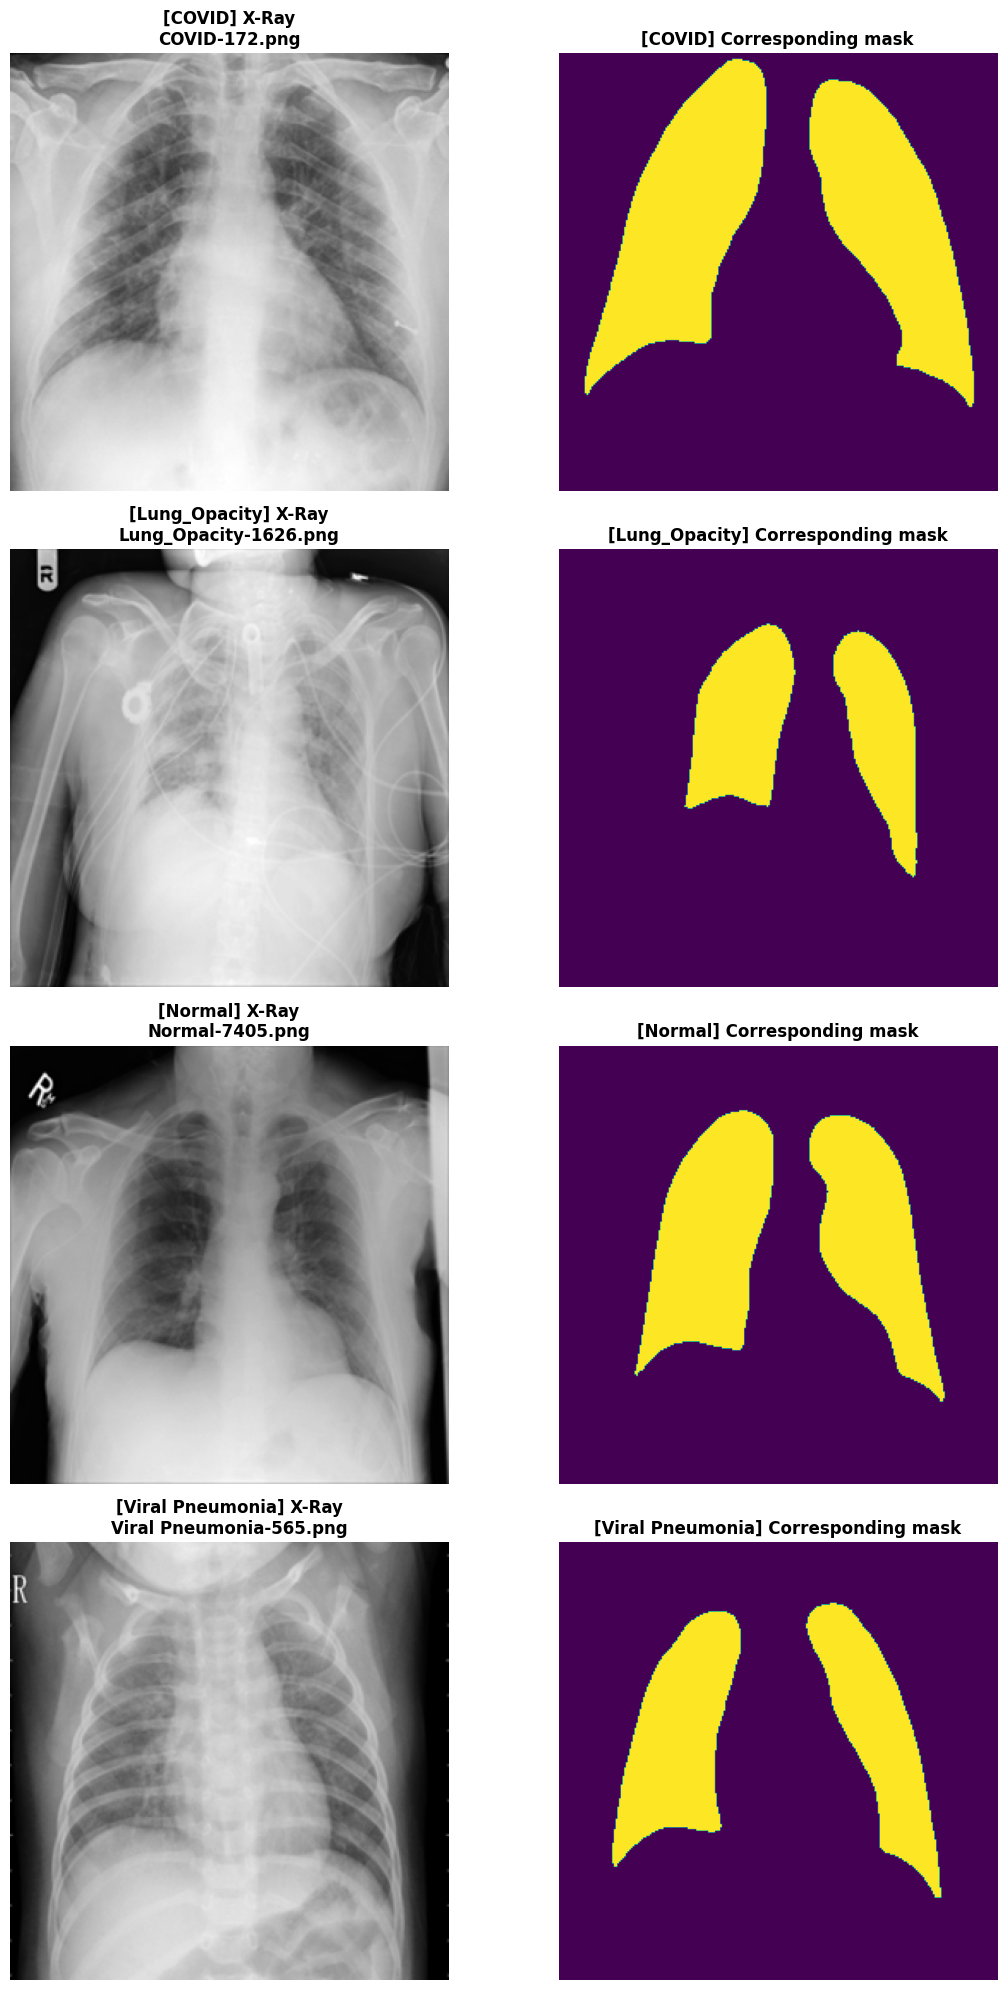

In [5]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

random.seed(67676767)

fig, axes = plt.subplots(len(CLASSES), 2, figsize=(12, 5 * len(CLASSES)))

if len(CLASSES) == 1:
    axes = np.expand_dims(axes, axis=0)

for i, cls in enumerate(CLASSES):
    img_dir = os.path.join(base_dir, cls, 'images')
    mask_dir = os.path.join(base_dir, cls, 'masks')

    valid_imgs = [f for f in os.listdir(img_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

    if not valid_imgs:
        raise RuntimeError(f"No images in {cls}")

    sample_img_name = random.choice(valid_imgs)
    img_path = os.path.join(img_dir, sample_img_name)

    try:
        img = Image.open(img_path).convert('L')
    except Exception as e:
        raise RuntimeError(f"Could not open image |{img_path}|. All images should be openable")

    mask_path = os.path.join(mask_dir, sample_img_name)

    if not os.path.exists(mask_path):
        name_without_ext = os.path.splitext(sample_img_name)[0]
        ext = os.path.splitext(sample_img_name)[1]
        mask_path_fallback = os.path.join(mask_dir, f"{name_without_ext}_mask{ext}")
        if os.path.exists(mask_path_fallback):
            mask_path = mask_path_fallback

    if os.path.exists(mask_path):
        try:
            mask = Image.open(mask_path).convert('L')
            mask_exists = True
        except Exception:
            mask = np.zeros_like(np.array(img))
            mask_exists = False
            # raise RuntimeError("Mask should always exist and be openable") ??
    else:
        mask = np.zeros_like(np.array(img))
        mask_exists = False
        # raise RuntimeError("Mask should always exist and be openable") ??

    axes[i, 0].imshow(img, cmap='gray')
    axes[i, 0].set_title(f"[{cls}] X-Ray\n{sample_img_name}", fontsize=12, fontweight='bold')
    axes[i, 0].axis('off')
    axes[i, 1].imshow(mask, cmap='viridis')

    if mask_exists:
        axes[i, 1].set_title(f"[{cls}] Corresponding mask", fontsize=12, fontweight='bold')
    else:
        axes[i, 1].set_title(f"[{cls}] No mask",fontsize=12, fontweight='bold', color='red')

    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

**А теперь статистика. Проверим что все файлы валидны и в принципе существуют**

In [6]:
VALID_EXTENSIONS = {'.png', '.jpg', '.jpeg'}

file_counts = {cls: {'images': 0, 'masks': 0, 'invalid_imgs': 0, 'invalid_masks': 0} for cls in CLASSES}
invalid_files_log = []
missing_masks_log = []

for cls in CLASSES:
    img_dir = os.path.join(base_dir, cls, 'images')
    mask_dir = os.path.join(base_dir, cls, 'masks')

    img_files = set()
    mask_files = set()

    if os.path.exists(img_dir):
        for f in os.listdir(img_dir):
            ext = os.path.splitext(f)[1].lower()
            if ext in VALID_EXTENSIONS:
                img_files.add(f)
                file_counts[cls]['images'] += 1

                try:
                    with Image.open(os.path.join(img_dir, f)) as img:
                        img.verify()
                except Exception:
                    file_counts[cls]['invalid_imgs'] += 1
                    invalid_files_log.append({'Class': cls, 'Type': 'Image', 'File': f})
            else:
                file_counts[cls]['invalid_imgs'] += 1
                invalid_files_log.append({'Class': cls, 'Type': 'Image', 'File': f, 'Reason': 'Bad Extension'})

    if os.path.exists(mask_dir):
        for f in os.listdir(mask_dir):
            ext = os.path.splitext(f)[1].lower()
            if ext in VALID_EXTENSIONS:
                mask_files.add(f)
                file_counts[cls]['masks'] += 1

                try:
                    with Image.open(os.path.join(mask_dir, f)) as mask:
                        mask.verify()
                except Exception:
                    file_counts[cls]['invalid_masks'] += 1
                    invalid_files_log.append({'Class': cls, 'Type': 'Mask', 'File': f})

    missing_in_masks = img_files - mask_files
    missing_in_imgs = mask_files - img_files

    if missing_in_masks:
        for m in missing_in_masks:
            missing_masks_log.append({'Class': cls, 'Missing': 'Mask', 'For_Image': m})
    if missing_in_imgs:
        for m in missing_in_imgs:
            missing_masks_log.append({'Class': cls, 'Missing': 'Image', 'For_Mask': m})

In [7]:
total_images = sum(file_counts[cls]['images'] for cls in CLASSES)
total_masks = sum(file_counts[cls]['masks'] for cls in CLASSES)
total_invalid = sum(file_counts[cls]['invalid_imgs'] + file_counts[cls]['invalid_masks'] for cls in CLASSES)
total_valid = total_images + total_masks - total_invalid
total_valid_files = (total_images - sum(file_counts[cls]['invalid_imgs'] for cls in CLASSES)) + \
                    (total_masks - sum(file_counts[cls]['invalid_masks'] for cls in CLASSES))
total_all_files = total_images + total_masks

overall_good_pct = (total_valid_files / total_all_files) * 100 if total_all_files > 0 else 0

print("~~~~~~~~~~~~~~~~~~~~~~~ FINAL DATASET SUMMARY ~~~~~~~~~~~~~~~~~~~~~")
print(f"Total images:   {total_images}")
print(f"Total masks:    {total_masks}")
print(f"Total valid imgs:         {total_valid_files} ({overall_good_pct:.2f}%)")
print(f"Total invalid imgs:       {total_all_files - total_valid_files} ({100 - overall_good_pct:.2f}%)")
print(f"Missing pairs (img <--> mask):  {len(missing_masks_log)}")
print("~" * 67)

summary_data = []
for cls in CLASSES:
    valid_imgs = file_counts[cls]['images'] - file_counts[cls]['invalid_imgs']
    valid_masks = file_counts[cls]['masks'] - file_counts[cls]['invalid_masks']
    summary_data.append({
        'Class': cls,
        'Total images': file_counts[cls]['images'],
        'Valid images': valid_imgs,
        'Total masks': file_counts[cls]['masks'],
        'Valid masks': valid_masks,
    })

df_summary = pd.DataFrame(summary_data)

df_summary

~~~~~~~~~~~~~~~~~~~~~~~ FINAL DATASET SUMMARY ~~~~~~~~~~~~~~~~~~~~~
Total images:   21165
Total masks:    21165
Total valid imgs:         42330 (100.00%)
Total invalid imgs:       0 (0.00%)
Missing pairs (img <--> mask):  0
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


,Class,Total images,Valid images,Total masks,Valid masks
0,COVID,3616,3616,3616,3616
1,Lung_Opacity,6012,6012,6012,6012
2,Normal,10192,10192,10192,10192
3,Viral Pneumonia,1345,1345,1345,1345


*Удачно. Все картинки валидны, поэтому процент плохих данных можно даже не строить*

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


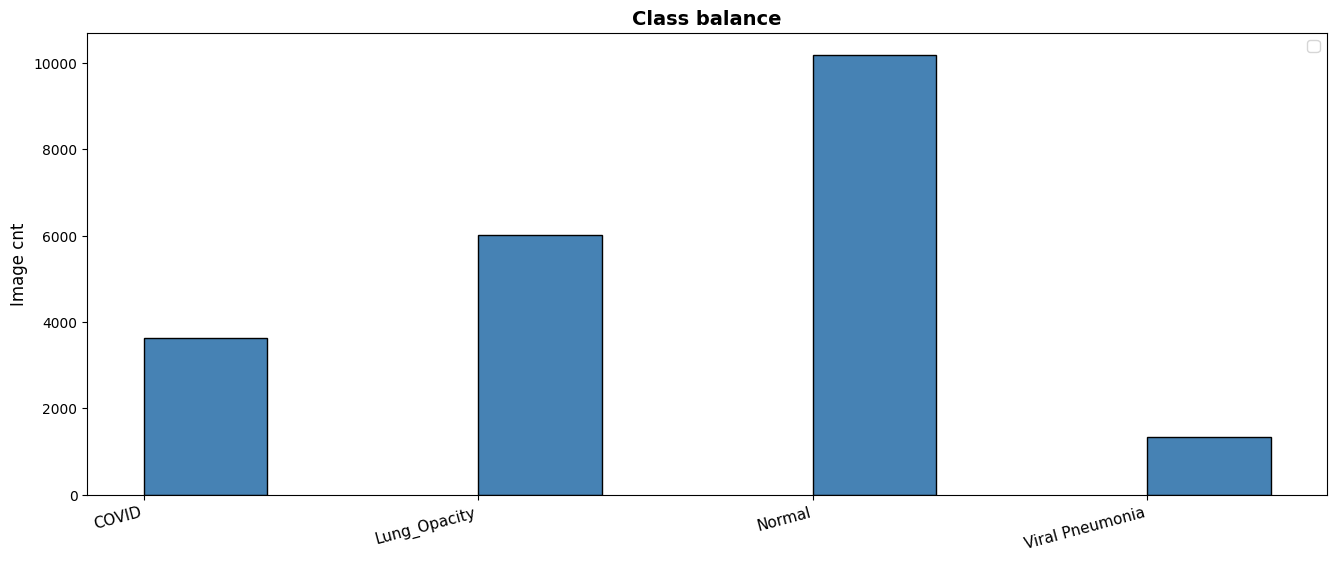

In [9]:
import numpy as np

fig, axes = plt.subplots(1, 1, figsize=(16, 6))

x_positions = np.arange(len(CLASSES))
width = 0.37

meta_counts = [metadata_stats.get(cls, 0) for cls in CLASSES]
valid_img_counts = df_summary['Valid images'].values

bars = axes.bar(x_positions + width / 2, valid_img_counts, width, label=None, color='steelblue', edgecolor='black')

axes.set_title('Class balance', fontsize=14, fontweight='bold')
axes.set_ylabel('Image cnt', fontsize=12)
axes.set_xticks(x_positions)
axes.set_xticklabels(CLASSES, rotation=15, ha='right', fontsize=11)
axes.legend(fontsize=11)

plt.show()

**Хороший датасет. К сожалению классы очень дизбалансны, а на Пневмонию почти нет картинок, зато невалидных данных нет**